# تحليل التعليقات العربية — دورة تعلّم آلة كاملة

دفتر مشروع **Riyadh Season AI Guide**. ندرّب مصنّفًا للنصوص العربية ونقارنه بخوارزمية أخرى وخط أساس، ثم نحفظ النموذج الذي تستخدمه خدمة الموقع.

التصنيفات: إيجابي، سلبي، ومحايد بمعنى موضوعي. النجوم وأسماء المراجعين ليست مدخلات. البيانات الأصلية من [ASTD](https://github.com/mahmoudnabil/ASTD)، مع توثيق النسخة والترخيص في `data/DATA_SOURCE.md`.

## 1. تجهيز المسارات والأدوات

قبل إعادة تنفيذ الدفتر: ثبّتي `requirements.txt` ونزّلي البيانات عبر `python ml/download_data.py` من مجلد المشروع. يعمل الدفتر من مجلد المشروع أو `ml`.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == 'ml':
    ROOT = ROOT.parent
assert (ROOT / 'ml').is_dir(), 'Open the notebook from the project directory or ml.'
ML = ROOT / 'ml'
sys.path.insert(0, str(ML))
from train import load_data, run_training, LABELS
from text_processing import normalize
from predictor import SentimentPredictor
DATA = ML / 'data' / 'Tweets.txt'
assert DATA.exists(), 'Run python ml/download_data.py before training.'
print('Environment ready.')


Environment ready.


## 2. قراءة البيانات وتنظيفها

نحتفظ بـPOS وNEG وOBJ. اسم NEUTRAL في الملف يقابل الفئة الذاتية المختلطة الموصوفة في الورقة، لذلك نستبعده. يُحذف التكرار بعد تطبيع النص، وتُحذف النصوص التي لها تصنيفات متعارضة. لا نعرض النصوص الخام أو معرّفات أشخاص في هذا الدفتر.

In [2]:
texts, labels, cleaning = load_data(DATA)
from collections import Counter
print('Raw label counts:', cleaning['raw_label_counts'])
print('Retained:', len(texts))
print('Class counts:', dict(Counter(labels)))
print('Conflicting normalized texts removed:', cleaning['conflicting_normalized_texts_removed'])


Raw label counts: {'OBJ': 6691, 'POS': 799, 'NEG': 1684, 'NEUTRAL': 832}
Retained: 8886
Class counts: {np.str_('neutral'): 6434, np.str_('positive'): 787, np.str_('negative'): 1665}
Conflicting normalized texts removed: 17


## 3. تطبيع العربية مع الاحتفاظ بالنفي

نزيل الروابط والإشارات والأرقام والتشكيل والتطويل، ونوحّد الألف والياء وتكرار الحروف والمسافات. كلمات مثل «ليس» و«لا» تبقى في النص. المثال التالي مكتوب للتوضيح، وليس نصًا من بيانات الاختبار.

In [3]:
sample = 'المكان لَيْسَ جميلاً، لكن أَحبّ التنظيم @example'
print(normalize(sample))
assert 'ليس' in normalize(sample)


المكان ليس جميلا، لكن احب التنظيم


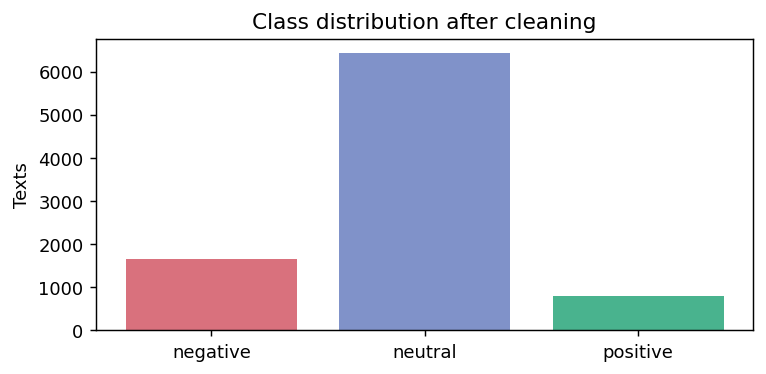

In [4]:
counts = Counter(labels)
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(LABELS, [counts[label] for label in LABELS], color=['#d9717d', '#8092c9', '#49b38e'])
ax.set_title('Class distribution after cleaning')
ax.set_ylabel('Texts')
fig.tight_layout()
plt.show()


## 4. تقسيم وتدريب ومقارنة

ينفذ `run_training` الخطوات الموجودة في `train.py`:

1. تقسيم طبقي بالبذرة 42: نحو 70% تدريب و15% تحقق و15% اختبار.
2. TF-IDF للكلمات (1–2) ومقاطع الحروف (3–5)، وتعلّم المفردات على التدريب فقط.
3. تدريب ComplementNB وLinearSVC، مع موازنة أثر الفئات.
4. اختيار الأعلى Macro-F1 على التحقق فقط.
5. تثبيت الاختيار، وإعادة الملاءمة على التدريب والتحقق، ثم اختبار النموذجين وخط الأساس.

لا يُستعمل الاختبار لاختيار النموذج أو ضبط المعاملات. تشغيل الخلية يعيد إنتاج النموذج والتقارير؛ أعيدي تشغيل خدمة الموقع بعدها.

In [5]:
report = run_training(DATA, output_root=ML)
print('Selected using validation:', report['selected_model'])
print('Split sizes:', {name: value['size'] for name, value in report['split'].items()})
print('Normalized text overlap:', report['normalized_text_overlap'])


ComplementNB validation macro-F1 0.5294
LinearSVC validation macro-F1 0.5299
MajorityBaseline validation macro-F1 0.28
ComplementNB test 0.6204 0.5514
LinearSVC test 0.7479 0.5585
MajorityBaseline test 0.7239 0.28
Selected: LinearSVC Model: astd-linearsvc-616de26a4e-seed42-v1
Selected using validation: LinearSVC
Split sizes: {'train': 6220, 'validation': 1333, 'test': 1333}
Normalized text overlap: 0


## 5. المقاييس الفعلية

Accuracy هي نسبة النصوص الصحيحة إجمالًا. Macro-F1 يعطي كل فئة وزنًا متساويًا، ويُستخدم للاختيار لأن الفئات غير متوازنة. هذه نتائج الاختبار على ASTD، وليست دقة مثبتة لتعليقات موسم الرياض.

In [6]:
print(f"{'Model':<20} {'Accuracy':>10} {'Macro-F1':>10}")
for name, result in report['test'].items():
    print(f"{name:<20} {result['accuracy']:>10.4f} {result['macro_f1']:>10.4f}")
print('Per-class report for selected model:')
for label in LABELS:
    print(label, report['test'][report['selected_model']]['classification_report'][label])


Model                  Accuracy   Macro-F1
ComplementNB             0.6204     0.5514
LinearSVC                0.7479     0.5585
MajorityBaseline         0.7239     0.2800
Per-class report for selected model:
negative {'precision': 0.5523012552301255, 'recall': 0.528, 'f1-score': 0.5398773006134969, 'support': 250.0}
neutral {'precision': 0.814382896015549, 'recall': 0.8683937823834197, 'f1-score': 0.8405215646940822, 'support': 965.0}
positive {'precision': 0.4153846153846154, 'recall': 0.2288135593220339, 'f1-score': 0.29508196721311475, 'support': 118.0}


## 6. مصفوفة الالتباس

الصف هو الفئة الحقيقية، والعمود هو التنبؤ. العناصر على القطر صحيحة، وما خارج القطر أخطاء تصنيف.

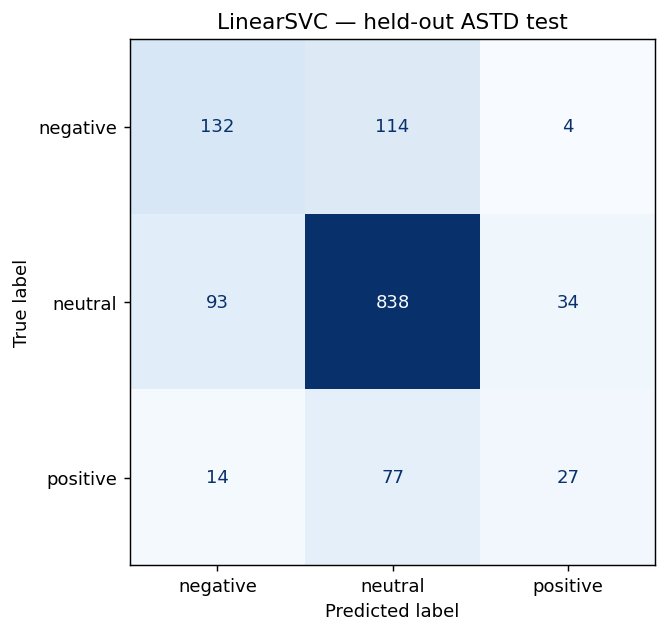

In [7]:
from sklearn.metrics import ConfusionMatrixDisplay
matrix = np.array(report['test'][report['selected_model']]['confusion_matrix'])
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(matrix, display_labels=LABELS).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title(report['selected_model'] + ' — held-out ASTD test')
fig.tight_layout()
plt.show()


## 7. تجربة الاستدلال

النموذج نفسه المحفوظ في `artifacts/sentiment.joblib` هو الذي يستخدمه الموقع. الأمثلة التالية توضيحية مكتوبة؛ لا تدخل في أرقام الاختبار. لا تُعرض نسبة ثقة غير معايرة.

In [8]:
predictor = SentimentPredictor(ML / 'artifacts' / 'sentiment.joblib')
examples = ['تجربة رائعة وممتعة شكرا لكم', 'خدمة سيئة وتجربة فاشلة ومخيبة للآمال', 'تقام الفعالية يوم الخميس في الرياض']
for text, prediction in zip(examples, predictor.predict(examples)):
    print(text, '→', prediction['label_ar'])


تجربة رائعة وممتعة شكرا لكم → إيجابي
خدمة سيئة وتجربة فاشلة ومخيبة للآمال → سلبي
تقام الفعالية يوم الخميس في الرياض → محايد


## 8. إعادة حساب النتيجة والتحقق من الفصل

نحسب المقاييس مرة أخرى من التنبؤات المحفوظة، ونتحقق من عدم تداخل بصمات النصوص بين المجموعات.

In [9]:
from sklearn.metrics import accuracy_score, f1_score
saved = np.load(ML / 'reports' / 'test_predictions.npz', allow_pickle=False)
selected = report['selected_model']
assert np.isclose(accuracy_score(saved['y_true'], saved[selected]), report['test'][selected]['accuracy'])
assert np.isclose(f1_score(saved['y_true'], saved[selected], average='macro'), report['test'][selected]['macro_f1'])
manifest = json.loads((ML / 'reports' / 'split_manifest.json').read_text())
partitions = {name: {row['text_sha256'] for row in rows} for name, rows in manifest.items()}
assert not partitions['train'] & partitions['test']
assert not partitions['validation'] & partitions['test']
assert not partitions['train'] & partitions['validation']
print('Saved metrics verified. No normalized-text overlap between partitions.')


Saved metrics verified. No normalized-text overlap between partitions.


## 9. ربط النموذج بالموقع

تشغّل `server.py` نموذجًا موثوقًا محليًا. PHP يرسل `{"texts":["..."]}` إلى `/predict`، ثم يعرض الفئة بالعربية. الخدمة لا تستقبل النجوم أو أسماء الزوار. ملخص الفعالية يعدّ النصوص المصنّفة فقط، وتستمر المراجعات بالعمل عند توقف التحليل.

الأمثلة السعودية التشخيصية المنفصلة في `../docs/domain_diagnostics.json` ليست مجموعة اختبار ميدانية ولا استُخدمت في التدريب أو اختيار النموذج.